# scATAC LEAF-1 embeddings versus coordinate binning across bin resolutions (Supplementary Figure 4)

Reads tables from `../data/` and writes figures to `../output/`.
Source analysis: `../../NOTEBOOK_PROVENANCE.tsv`.

Four scatter panels (300 kb, 100 kb, 30 kb, 10 kb bins). Each point is one of the
102 one-vs-all cell types; the y-axis is the AUC of the LEAF-1 embedding classifier
and the x-axis the AUC of the coordinate-binning baseline at that resolution. Both
axes are the mean of the five per-fold AUCs, as in the main-figure panel
(`scatac_leaf1_vs_coordinate_binning`, which is panel c here). The dashed diagonal
marks equal performance.

Revision of the published leaf-1-figures notebook of the same name, which put the
pooled out-of-fold LEAF-1 AUC (`scatac_task_metrics.csv` `auc`) against the
fold-mean binning AUCs. Rows of the source table are indexed by the number of
genome-wide bins; panels are labelled by bin size (10,000 bins = 300 kb ...
300,000 bins = 10 kb).

Panel:
- `scatac_embedding_vs_binning_resolution`: a-d, 300 / 100 / 30 / 10 kb bins.


In [1]:
from pathlib import Path
import sys

# Self-contained: works when run from notebook/, from the modality folder, or from the repo root.
nb_dir = Path.cwd()
if (nb_dir / "data").exists() and (nb_dir / "output").exists():
    MOD_DIR = nb_dir
elif (nb_dir.parent / "data").exists():
    MOD_DIR = nb_dir.parent
else:
    MOD_DIR = nb_dir
DATA = MOD_DIR / "data"
OUT = MOD_DIR / "output"
OUT.mkdir(exist_ok=True)

# Locate the shared style helper (src/leaf1figures) by walking up.
_p = nb_dir
while _p != _p.parent and not (_p / "src" / "leaf1figures").exists():
    _p = _p.parent
sys.path.insert(0, str(_p / "src"))

from leaf1figures.style import OKABE_ITO, savefig, set_paper_style
set_paper_style()
print("DATA:", DATA.relative_to(_p))
print("OUT :", OUT.relative_to(_p))

DATA: scatac/data
OUT : scatac/output


In [2]:
# ── Constants and data ────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter

# Supplementary Figure 4's rcParams, with leaf-1-figures' shared font order.
SUPP4_RC = {
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "DejaVu Sans", "Helvetica", "Liberation Sans"],
    "font.size": 6, "axes.titlesize": 7, "axes.labelsize": 6,
    "xtick.labelsize": 5, "ytick.labelsize": 5, "legend.fontsize": 5,
    "axes.linewidth": 0.5, "xtick.major.width": 0.5, "ytick.major.width": 0.5,
}
# Method name in the per-fold table -> panel label (bin count -> bin size)
BIN_LABEL = {"Bin 10k": "300 kb", "Bin 30k": "100 kb", "Bin 100k": "30 kb", "Bin 300k": "10 kb"}

kfold = pd.read_csv(DATA / "scatac_coordinate_binning_auc_by_fold.csv", float_precision="round_trip")
assert kfold.groupby(["Target", "Method"]).size().eq(5).all()
# Same reduction for every method: mean of the five per-fold AUCs.
mean_auc = kfold.groupby(["Target", "Method"])["AUC"].mean().unstack("Method")
mean_auc = mean_auc[["Embedding", *BIN_LABEL]]
assert len(mean_auc) == 102 and mean_auc.notna().all().all()
print(mean_auc.mean().round(4).to_string())

Method
Embedding    0.9355
Bin 10k      0.9225
Bin 30k      0.8887
Bin 100k     0.8132
Bin 300k     0.7290


saved: scatac/output/scatac_embedding_vs_binning_resolution.pdf
saved: scatac/output/scatac_embedding_vs_binning_resolution.png
saved: scatac/output/scatac_embedding_vs_binning_resolution.svg
saved: scatac/output/scatac_embedding_vs_binning_resolution.tsv


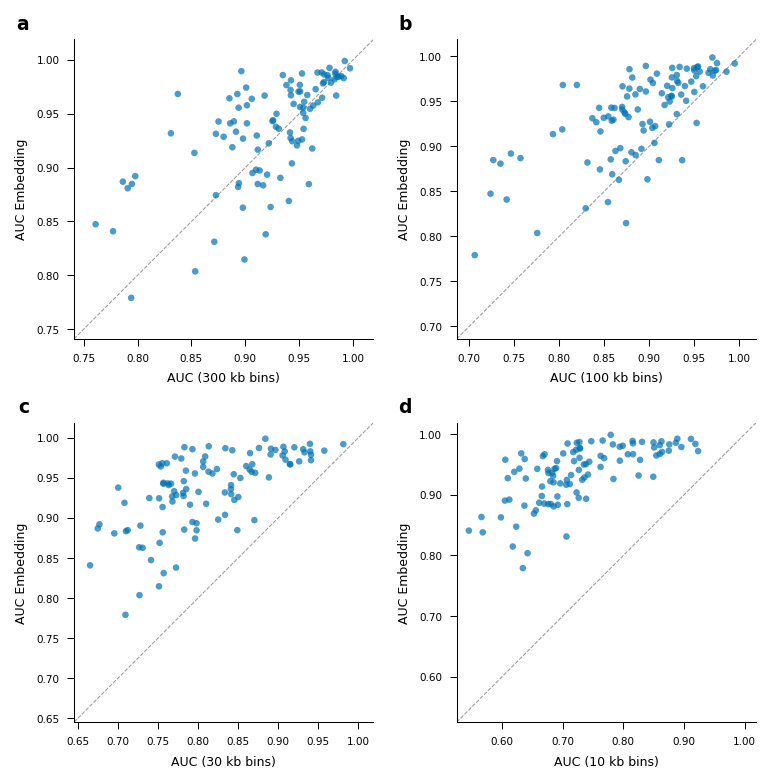

In [3]:
# ── Figure ─────────────────────────────────────────────────────────────────────
y = mean_auc["Embedding"].to_numpy()

with plt.rc_context(SUPP4_RC):
    fig, axes = plt.subplots(2, 2, figsize=(5.2, 5.2))
    for ax, (method, lab), letter in zip(axes.ravel(), BIN_LABEL.items(), "abcd"):
        x = mean_auc[method].to_numpy()
        ax.scatter(x, y, c=OKABE_ITO["blue"], s=10, alpha=0.7,
                   edgecolors="none", zorder=3, rasterized=True)
        lo = min(x.min(), y.min()) - 0.02           # per-panel square limits, as published
        hi = max(x.max(), y.max()) + 0.02
        ax.plot([lo, hi], [lo, hi], ls="--", color="0.6", lw=0.5, zorder=1)
        ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect("equal")
        for axis in (ax.xaxis, ax.yaxis):                # two decimals on every panel
            axis.set_major_formatter(FormatStrFormatter("%.2f"))
        ax.set_xlabel(f"AUC ({lab} bins)", fontsize=6)
        ax.set_ylabel("AUC Embedding", fontsize=6)
        ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
        ax.text(-0.15, 1.02, letter, transform=ax.transAxes, fontsize=9,
                fontweight="bold", va="bottom", ha="right")
    plt.tight_layout()
    src = mean_auc.rename(columns={m: f"bin_{l.replace(' ', '')}_auc" for m, l in BIN_LABEL.items()}
                          | {"Embedding": "leaf1_auc"}).reset_index().rename(columns={"Target": "target"})
    savefig(fig, OUT, "scatac_embedding_vs_binning_resolution", data=src)
    plt.show()

In [4]:
# ── Numbers for the figure legend ─────────────────────────────────────────────
for method, lab in BIN_LABEL.items():
    d = mean_auc["Embedding"] - mean_auc[method]
    print(f"{lab:>6}: embedding {mean_auc.Embedding.mean():.3f}, bins {mean_auc[method].mean():.3f}; "
          f"embedding higher in {(d > 0).sum()}/{len(d)}, median \u0394AUC {d.median():+.4f}")

300 kb: embedding 0.935, bins 0.922; embedding higher in 61/102, median ΔAUC +0.0062
100 kb: embedding 0.935, bins 0.889; embedding higher in 92/102, median ΔAUC +0.0359
 30 kb: embedding 0.935, bins 0.813; embedding higher in 102/102, median ΔAUC +0.1153
 10 kb: embedding 0.935, bins 0.729; embedding higher in 102/102, median ΔAUC +0.2133
